# Дипломный проект. Оценка эффективности маркетинговых коммуникаций на основе A/B-тестирования
## Блок 1. Импорт библиотек и первичная загрузка данных

In [62]:
import pandas as pd
import numpy as np

df_data = pd.read_excel('Новый диплом датасет update.xlsx', sheet_name='Данные')
df_clients = pd.read_excel('Новый диплом датасет update.xlsx', sheet_name='Clients')
df_regions = pd.read_excel('Новый диплом датасет update.xlsx', sheet_name='Region_dict')
df_data.head()

,id_order,id_client,amt_payment,dtime_pay
0,100238,194569.0,5373.0,2022-07-17 21:48:15.896
1,100242,191056.0,4151.0,2022-07-07 03:09:39.699
2,100249,200049.0,5688.0,2022-07-29 13:25:59.976
3,100258,206161.0,4330.0,2022-08-15 22:55:02.538
4,100267,190945.0,5488.0,2022-07-05 19:46:47.174


In [63]:
df_payments_agg = df_data.groupby('id_client')['amt_payment'].sum().reset_index()
df_merged = pd.merge(df_clients, df_payments_agg, on='id_client', how='left')

In [64]:
df_merged['amt_payment'] = df_merged['amt_payment'].fillna(0)
df_final = pd.merge(df_merged, df_regions, on='id_trading_point', how='left')

In [65]:
df_final['flag_payment'] = np.where(df_final['amt_payment'] > 0, 1, 0)

## Блок 2. Проверка качества данных (Data Quality) и очистка от пересечений

In [66]:
# 1. Проверяем размер таблиц до очистки
print(f"Строк в логе продаж: {len(df_data)}")
print(f"Строк в базе клиентов: {len(df_clients)}")

# 2. Удаляем пустые значения в критически важных полях (Data Quality)
df_data = df_data.dropna(subset=['id_client', 'amt_payment'])
df_clients = df_clients.dropna(subset=['id_client', 'nflag_test'])

# 3. Ищем клиентов, которые из-за бага сплит-системы попали в обе группы (пересечения)
group_0 = set(df_clients[df_clients['nflag_test'] == 0]['id_client'])
group_1 = set(df_clients[df_clients['nflag_test'] == 1]['id_client'])
intersected_clients = group_0.intersection(group_1)

print(f"Найдено пересекающихся клиентов (в группах А и B одновременно): {len(intersected_clients)}")

# 4. Удаляем пересекающихся клиентов из базы, чтобы не размывать стат-тесты
df_clients = df_clients[~df_clients['id_client'].isin(intersected_clients)]
print(f"База клиентов после очистки от пересечений: {len(df_clients)}")

Строк в логе продаж: 37989
Строк в базе клиентов: 55605
Найдено пересекающихся клиентов (в группах А и B одновременно): 0
База клиентов после очистки от пересечений: 55605


## Блок 3. Создание автоматизированных функций для проверки статистических гипотез

In [67]:
from scipy import stats

def test_calc(r1, r2, alpha=0.05):
    # Вычисляем t-критерий и p-value
    t_stat, p_value = stats.ttest_ind(r1, r2, equal_var=False) # t-тест Уэлча (безопаснее)
    
    print(f"t-статистика: {t_stat:.4f}")
    print(f"p-value: {p_value:.4f}")
    
    # Проверяем значимость
    if p_value < alpha:
        print("Результат: Разница между средними чеками СТАТИСТИЧЕСКИ ЗНАЧИМА (отклоняем H0).")
    else:
        print("Результат: Статистически значимой разницы между средними чеками НЕ ОБНАРУЖЕНО.")
        
    return t_stat, p_value

In [68]:
def mann_whitney_func(r1, r2, alpha=0.05):
    from scipy import stats
    u_stat, p_value = stats.mannwhitneyu(r1, r2, alternative='two-sided')

    print(f"U-статистика: {u_stat:.4f}")
    print(f"p-value: {p_value:.4f}")

    if p_value < alpha:
        print("Результат: Разница распределений СТАТИСТИЧЕСКИ ЗНАЧИМА (отклоняем H0).")
    else:
        print("Результат: Статистически значимой разницы распределений НЕ ОБНАРУЖЕНО.")

    return u_stat, p_value

## Блок 4. Поиск и удаление аномальных торговых точек. Визуализация распределения платежей

In [69]:
# 1. Считаем сумму платежей и количество клиентов по каждой точке и группе
shop_stats = df_final.groupby(['id_trading_point', 'nflag_test']).agg(
    total_pay=('amt_payment', 'sum'),
    clients_count=('id_client', 'count')
).reset_index()

# 2. Находим "проблемные" точки, где нет денег или пустует группа
# Делаем сводную таблицу, чтобы проверить обе группы (0 и 1) для каждого магазина
shop_pivot = shop_stats.pivot(index='id_trading_point', columns='nflag_test', values=['total_pay', 'clients_count']).fillna(0)

# Условие для удаления: если сумма платежей = 0 или кол-во клиентов = 0 в любой из групп
bad_shops = shop_pivot[
    (shop_pivot[('total_pay', 0)] == 0) | (shop_pivot[('total_pay', 1)] == 0) |
    (shop_pivot[('clients_count', 0)] == 0) | (shop_pivot[('clients_count', 1)] == 0)
].index.tolist()

print(f"Список «мертвых» торговых точек для удаления: {bad_shops}")

# 5. Расчет общих результатов: отбрасываем эти точки (Пункт 1)
df_cleaned = df_final[~df_final['id_trading_point'].isin(bad_shops)]

Список «мертвых» торговых точек для удаления: [1, 4, 7, 26, 46, 228, 603, 739, 800, 810, 866, 1015, 1099]


In [70]:
# Выборки для среднего чека (берем только реальные оплаты > 0)
pay_control = df_cleaned[(df_cleaned['nflag_test'] == 0) & (df_cleaned['amt_payment'] > 0)]['amt_payment']
pay_test = df_cleaned[(df_cleaned['nflag_test'] == 1) & (df_cleaned['amt_payment'] > 0)]['amt_payment']
# Выборки для конверсии (ряды нулей и единиц из flag_payment)
conversion_control = df_cleaned[df_cleaned['nflag_test'] == 0]['flag_payment']
conversion_test = df_cleaned[df_cleaned['nflag_test'] == 1]['flag_payment']

# 3. Сравниваем средние платежи (t-тест)
print("=== Сравнение средних чеков (t-тест) ===")
test_calc(pay_control, pay_test)

# 4. Сравниваем конверсию (t-тест на нулях и единицах)
print("\n=== Сравнение конверсии в платеж (t-тест) ===")
test_calc(conversion_control, conversion_test)

# 5. Сравниваем распределения платежей (Манна-Уитни)
print("\n=== Сравнение распределений чеков (Манна-Уитни) ===")
mann_whitney_func(pay_control, pay_test)

=== Сравнение средних чеков (t-тест) ===
t-статистика: -3.8675
p-value: 0.0001
Результат: Разница между средними чеками СТАТИСТИЧЕСКИ ЗНАЧИМА (отклоняем H0).

=== Сравнение конверсии в платеж (t-тест) ===
t-статистика: -9.1619
p-value: 0.0000
Результат: Разница между средними чеками СТАТИСТИЧЕСКИ ЗНАЧИМА (отклоняем H0).

=== Сравнение распределений чеков (Манна-Уитни) ===
U-статистика: 68804794.0000
p-value: 0.0000
Результат: Разница распределений СТАТИСТИЧЕСКИ ЗНАЧИМА (отклоняем H0).


(np.float64(68804794.0), np.float64(2.2033623055076106e-05))

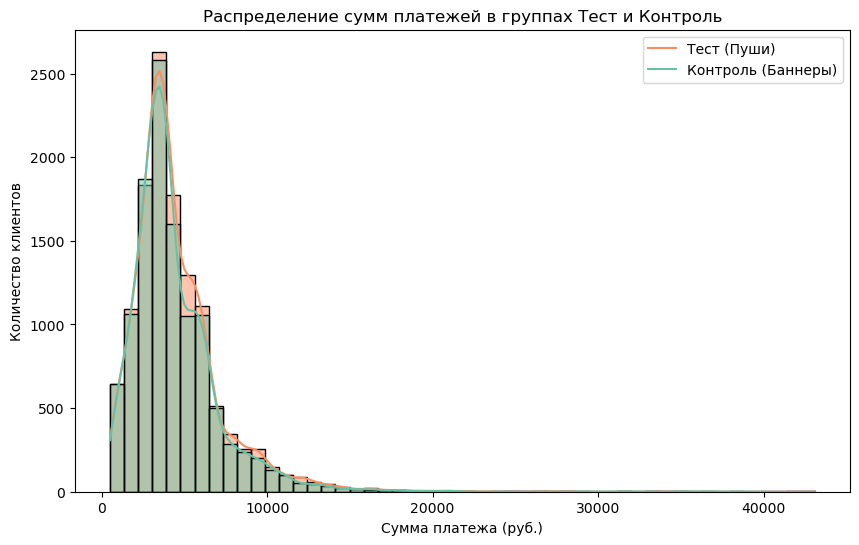

In [71]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
# Берем только тех, кто реально совершил платеж (>0), чтобы нулевые клиенты не забивали график
sns.histplot(data=df_cleaned[df_cleaned['amt_payment'] > 0], 
             x='amt_payment', 
             hue='nflag_test', 
             kde=True, 
             palette='Set2', 
             bins=50)

plt.title('Распределение сумм платежей в группах Тест и Контроль')
plt.xlabel('Сумма платежа (руб.)')
plt.ylabel('Количество клиентов')
plt.legend(labels=['Тест (Пуши)', 'Контроль (Баннеры)'])
plt.show()

## Блок 5. Анализ общих результатов эксперимента и сегментация по ключевым регионам (Москва, Санкт-Петербург)

In [72]:
def analyze_city(city_name, df):
    print(f"\n" + "="*40)
    print(f"📊 АНАЛИЗ ДАННЫХ ДЛЯ ГОРОДА: {city_name.upper()}")
    print("="*40)
    
    # Фильтруем датасет по конкретному городу
    df_city = df[df['city'] == city_name]
    
    # Выборки для чеков и конверсии внутри этого города
    p_control = df_city[(df_city['nflag_test'] == 0) & (df_city['amt_payment'] > 0)]['amt_payment']
    p_test = df_city[(df_city['nflag_test'] == 1) & (df_city['amt_payment'] > 0)]['amt_payment']
    
    c_control = df_city[df_city['nflag_test'] == 0]['flag_payment']
    c_test = df_city[df_city['nflag_test'] == 1]['flag_payment']
    
    # Запуск тестов
    print("\n1. Тестирование средних чеков (t-тест):")
    test_calc(p_control, p_test)
    
    print("\n2. Тестирование конверсии (t-тест):")
    test_calc(c_control, c_test)
    
    print("\n3. Тестирование распределений (Манна-Уитни):")
    mann_whitney_func(p_control, p_test)

# 1. Запускаем для Москвы
analyze_city('Москва', df_cleaned)

# 2. Запускаем для Санкт-Петербурга
analyze_city('Санкт-Петербург', df_cleaned)


📊 АНАЛИЗ ДАННЫХ ДЛЯ ГОРОДА: МОСКВА

1. Тестирование средних чеков (t-тест):
t-статистика: -4.6372
p-value: 0.0000
Результат: Разница между средними чеками СТАТИСТИЧЕСКИ ЗНАЧИМА (отклоняем H0).

2. Тестирование конверсии (t-тест):
t-статистика: -6.4278
p-value: 0.0000
Результат: Разница между средними чеками СТАТИСТИЧЕСКИ ЗНАЧИМА (отклоняем H0).

3. Тестирование распределений (Манна-Уитни):
U-статистика: 4629615.0000
p-value: 0.0000
Результат: Разница распределений СТАТИСТИЧЕСКИ ЗНАЧИМА (отклоняем H0).

📊 АНАЛИЗ ДАННЫХ ДЛЯ ГОРОДА: САНКТ-ПЕТЕРБУРГ

1. Тестирование средних чеков (t-тест):
t-статистика: -2.3074
p-value: 0.0211
Результат: Разница между средними чеками СТАТИСТИЧЕСКИ ЗНАЧИМА (отклоняем H0).

2. Тестирование конверсии (t-тест):
t-статистика: -9.3525
p-value: 0.0000
Результат: Разница между средними чеками СТАТИСТИЧЕСКИ ЗНАЧИМА (отклоняем H0).

3. Тестирование распределений (Манна-Уитни):
U-статистика: 2345701.5000
p-value: 0.0893
Результат: Статистически значимой разницы расп

## Блок 6. Поточечный расчет метрик A/B-теста и генерация многостраничного отчета для Excel-калькулятора

In [73]:
!pip install xlsxwriter

In [74]:
import pandas as pd
from scipy import stats

# 1. Готовим пустой список для сбора результатов (Пункт 1)
results_list = []

# Составим список всех уникальных торговых точек и их городов
unique_shops = df_cleaned[['city', 'id_trading_point']].drop_duplicates()

# Запускаем цикл по всем магазинам (Пункт 1)
for idx, row in unique_shops.iterrows():
    city = row['city']
    shop_id = row['id_trading_point']
    
    # Фильтруем данные по конкретной торговой точке
    df_shop = df_cleaned[df_cleaned['id_trading_point'] == shop_id]
    
    # Выборки для среднего чека (только платящие)
    p_control = df_shop[(df_shop['nflag_test'] == 0) & (df_shop['amt_payment'] > 0)]['amt_payment']
    p_test = df_shop[(df_shop['nflag_test'] == 1) & (df_shop['amt_payment'] > 0)]['amt_payment']
    
    # Считаем базовые метрики для таблицы (Пункт 2)
    mean_control = p_control.mean() if len(p_control) > 0 else 0
    mean_test = p_test.mean() if len(p_test) > 0 else 0
    
    # Проводим Манна-Уитни (он стабильнее для отдельных точек)
    if len(p_control) > 3 and len(p_test) > 3: # проверяем, что есть данные для теста
        _, p_value = stats.mannwhitneyu(p_control, p_test, alternative='two-sided')
    else:
        p_value = 1.0 # если данных мало, считаем разницу незначимой
        
    # 3. Присваиваем один из трех лейблов (Пункт 3)
    if p_value < 0.05: # Разница значима
        if mean_test > mean_control:
            label = 'Пуши эффективнее (Тест выиграл)'
        else:
            label = 'Баннеры эффективнее (Контроль выиграл)'
    else:
        label = 'Разницы нет (Статзначимых различий не обнаружено)'
        
    # Добавляем строку в наш список
    results_list.append({
        'Город': city,
        'ID Точки': shop_id,
        'Ср. чек Контроль': round(mean_control, 2),
        'Ср. чек Тест': round(mean_test, 2),
        'p-value': round(p_value, 4),
        'Результат': label
    })

# Превращаем список в итоговый датафрейм
df_results = pd.DataFrame(results_list)

# 4. Выгружаем на три разных листа в зависимости от лейбла (Пункт 4)
with pd.ExcelWriter('AB_Test_Shops_Report.xlsx', engine='xlsxwriter') as writer:
    # Лист 1: Где пуши сработали круче
    df_push = df_results[df_results['Результат'] == 'Пуши эффективнее (Тест выиграл)']
    df_push.to_excel(writer, sheet_name='Пуши_Лидеры', index=False)
    
    # Лист 2: Где баннеры остались впереди
    df_banner = df_results[df_results['Результат'] == 'Баннеры эффективнее (Контроль выиграл)']
    df_banner.to_excel(writer, sheet_name='Баннеры_Лидеры', index=False)
    
    # Лист 3: Где статзначимой разницы не нашлось
    df_no_diff = df_results[df_results['Результат'] == 'Разницы нет (Статзначимых различий не обнаружено)']
    df_no_diff.to_excel(writer, sheet_name='Без_изменений', index=False)

print("Ура! Многостраничный Excel-отчет успешно сгенерирован и сохранен!")

Ура! Многостраничный Excel-отчет успешно сгенерирован и сохранен!


In [75]:
import pandas as pd
import numpy as np

# 1. Считаем общее количество наблюдений для расчета процентов (percent_count)
total_observations = len(df_cleaned)

# 2. Группируем данные по городам и торговым точкам, рассчитывая метрики отдельно для Теста (1) и Контроля (0)
# Для этого сделаем сводную таблицу (pivot_table), чтобы получить колонки для каждой группы на одной строке
shop_metrics = df_cleaned.groupby(['city', 'id_trading_point', 'nflag_test']).agg(
    obs_count=('id_client', 'count'),
    avg_pay=('amt_payment', lambda x: x[x > 0].mean()), # средний чек только для платящих
    std_pay=('amt_payment', lambda x: x[x > 0].std())   # стандартное отклонение только для платящих
).reset_index()

# Разворачиваем таблицу, чтобы группы 0 и 1 встали в отдельные столбцы
df_pivot = shop_metrics.pivot(
    index=['city', 'id_trading_point'], 
    columns='nflag_test', 
    values=['obs_count', 'avg_pay', 'std_pay']
).fillna(0)

# Сбрасываем мульти-индексы колонок для удобства
df_pivot.columns = [f"{col[0]}_{col[1]}" for col in df_pivot.columns]
df_pivot = df_pivot.reset_index()

# 3. Собираем финальную таблицу строго по названиям полей из ТЗ диплома:
df_final_report = pd.DataFrame()

df_final_report['city'] = df_pivot['city']
df_final_report['id_trading_point'] = df_pivot['id_trading_point']

# Количество наблюдений
df_final_report['count_test'] = df_pivot['obs_count_1'].astype(int)
df_final_report['count_control'] = df_pivot['obs_count_0'].astype(int)
df_final_report['count_all'] = df_final_report['count_test'] + df_final_report['count_control']

# Процент от всех наблюдений датасета
df_final_report['percent_count'] = round((df_final_report['count_all'] / total_observations) * 100, 2)

# Средние платежи (чеки)
df_final_report['avg_payment_test'] = round(df_pivot['avg_pay_1'], 2)
df_final_report['avg_payment_control'] = round(df_pivot['avg_pay_0'], 2)

# Разница между средними платежами
df_final_report['diff'] = round(df_final_report['avg_payment_test'] - df_final_report['avg_payment_control'], 2)

# Стандартное отклонение (сигма) платежей в тестовой группе
df_final_report['sigma_test'] = round(df_pivot['std_pay_1'], 2)

print("Финальная витрина данных успешно собрана строго по спецификации диплома!")

Финальная витрина данных успешно собрана строго по спецификации диплома!


In [76]:
import pandas as pd
import numpy as np
from scipy import stats

# 1. Готовим список под строки итогового отчета
report_rows = []
total_all_observations = len(df_cleaned)

# Получаем уникальные пары Город - Точка
unique_points = df_cleaned[['city', 'id_trading_point']].drop_duplicates()

# 2. Запускаем цикл расчета по каждой торговой точке
for idx, row in unique_points.iterrows():
    city_name = row['city']
    shop_id = row['id_trading_point']
    
    # Фильтруем данные по конкретному магазину
    df_shop = df_cleaned[df_cleaned['id_trading_point'] == shop_id]
    
    # Полные выборки для подсчета общего количества людей (и платящие, и неплатящие)
    all_control = df_shop[df_shop['nflag_test'] == 0]
    all_test = df_shop[df_shop['nflag_test'] == 1]
    
    count_c = len(all_control)
    count_t = len(all_test)
    count_all = count_c + count_t
    percent_count = round((count_all / total_all_observations) * 100, 2)
    
    # Выборки только по платящим клиентам для расчета чеков и t-теста
    pay_c = all_control[all_control['amt_payment'] > 0]['amt_payment']
    pay_t = all_test[all_test['amt_payment'] > 0]['amt_payment']
    
    # Считаем средние чеки и сигмы
    avg_c = round(pay_c.mean(), 2) if len(pay_c) > 0 else 0
    avg_t = round(pay_t.mean(), 2) if len(pay_t) > 0 else 0
    diff_val = round(avg_t - avg_c, 2)
    
    sigma_c = round(pay_c.std(), 2) if len(pay_c) > 1 else 0
    sigma_t = round(pay_t.std(), 2) if len(pay_t) > 1 else 0
    
    # 3. Проводим t-тест Стьюдента (применяем тест Уэлча на случай разных дисперсий)
    if len(pay_c) > 3 and len(pay_t) > 3:
        ttest_stat, p_val = stats.ttest_ind(pay_t, pay_c, equal_var=False)
    else:
        ttest_stat, p_val = 0, 1.0 # если данных нет, разница по умолчанию не значима
        
    # 4. Логика флага-лейбла по ТЗ 13-го слайда
    if p_val < 0.05: # Разница статистически значима
        if diff_val > 0:
            result_label = 'Положительный исход'
        else:
            result_label = 'Отрицательный исход'
    else: # Разницы на самом деле нет
        result_label = 'Нейтральный исход'
        
    # Добавляем данные в список
    report_rows.append({
        'city': city_name,
        'id_trading_point': shop_id,
        'count_test': count_t,
        'count_control': count_c,
        'count_all': count_all,
        'percent_count': percent_count,
        'avg_payment_test': avg_t,
        'avg_payment_control': avg_c,
        'diff': diff_val,
        'sigma_test': sigma_t,
        'sigma_control': sigma_c,
        'ttest': round(ttest_stat, 4),
        'pvalue_test': round(p_val, 4),
        'flag': result_label
    })

# Превращаем в итоговый датафрейм
df_final_report = pd.DataFrame(report_rows)
print("Ура! Полная витрина диплома успешно собрана!")

Ура! Полная витрина диплома успешно собрана!
